# Rocket Model Analysis

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(root))

In [3]:
"""
ALL SYMBOLS, CONSTANTS AND FUNCTIONS
"""
# Variables
t = sp.Symbol("t")
# Adjustable parameters
k1, k2, T = sp.symbols("k1 k2 T")
# Constants
ka = 0.0655         # actuator's push gain
tm = 0.9370314843   # engine bandwidth (1/tm = 1.0672)
c0 = 9.81           # gravitational coupling
mu = 1.20           # aerodynamic rigidity
ad = 0.35           # aerodynamic damping
kd = 8.5            # nozzle's effectivity
ke = 0.12           # coupling from missalignment
ts = 0.05           # servo's bandwidth (1/ts = 20)
lmd = 0.6           # IMO's speed-position ratio
# Inputs
u1 = sp.Function('u1')(t)
u2 = sp.Function('u2')(t)
inputs = [u1, u2]
# States
acc = sp.Function('a')(t)   # axial acceleration
theta = sp.Function('0')(t) # angular velocity
omega = sp.Function('w')(t) # momentum balacing
delta = sp.Function('d')(t) # nozzle's servo dynamic
states = [acc, theta, omega, delta]
# Outputs
y1 = sp.Function('y1')(t)
y2 = sp.Function('y2')(t)
outputs = [y1, y2]

"""
EQUATION SYSTEM DEFINITION
"""
# States equation system
dx1 = sp.Eq(acc.diff(t), -((1 + k1*ka)/tm)*acc - c0*theta + ((k1*ka)/tm)*u2)
dx2 = sp.Eq(theta.diff(t), omega)
dx3 = sp.Eq(omega.diff(t), mu*theta - ad*omega + kd*delta + ke*acc)
dx4 = sp.Eq(delta.diff(t), -(1/ts)*delta -(k2/ts)*theta - ((lmd*k2)/ts)*omega + (k2/ts)*u2)
state_system = [dx1, dx2, dx3, dx4]
# Output equation system
out1 = sp.Eq(y1, acc)
out2 = sp.Eq(y2, delta)
output_system = [out1, out2]

In [4]:
from src.system_rep import get_all_matrixes

A, B, C, D = get_all_matrixes(state_system, output_system, states, inputs, outputs)
print("A = ", A)
print("B = ", B)
print("C = ", C)
print("D = ", D)

A =  [[-0.0699015999968572*k1 - 1.06719999995202, -9.81000000000000, 0, 0], [0, 0, 1, 0], [0.120000000000000, 1.20000000000000, -0.350000000000000, 8.50000000000000], [0, -20.0*k2, -12.0*k2, -20.0000000000000]]
B =  [[0, 0.0699015999968572*k1], [0, 0], [0, 0], [0, 20.0*k2]]
C =  [[1, 0, 0, 0], [0, 0, 0, 1]]
D =  [[0, 0], [0, 0]]


In [5]:
from src.system_rep import get_all_matrixes

# Parameter definition
values = [(k1, 1), (k2, 1), (T, 1)]
state_system_n = [eq.subs(values) for eq in state_system]
output_system_n = [eq.subs(values) for eq in output_system]

# Getting matrixes representation
A, B, C, D = get_all_matrixes(state_system_n, output_system_n, states, inputs, outputs)
print("A = ", A)
print("B = ", B)
print("C = ", C)
print("D = ", D)

A =  [[-1.13710159994888, -9.81000000000000, 0, 0], [0, 0, 1, 0], [0.120000000000000, 1.20000000000000, -0.350000000000000, 8.50000000000000], [0, -20.0000000000000, -12.0000000000000, -20.0000000000000]]
B =  [[0, 0.0699015999968572], [0, 0], [0, 0], [0, 20.0000000000000]]
C =  [[1, 0, 0, 0], [0, 0, 0, 1]]
D =  [[0, 0], [0, 0]]


## System's Output

In [6]:
from scipy import signal

# Inputs definition
def f1(t):
    return np.where(t >= 1.0, 2.0, 0)
def f2(t):
    return np.sin(0.5 * t)

T = np.linspace(0.0, 20.0, 1000)
U = np.column_stack((f1(T), f2(T)))

# Output calculation
state_space = signal.StateSpace(A, B, C, D)
t_out, y_out, x_out = signal.lsim(state_space, U=U, T=T)

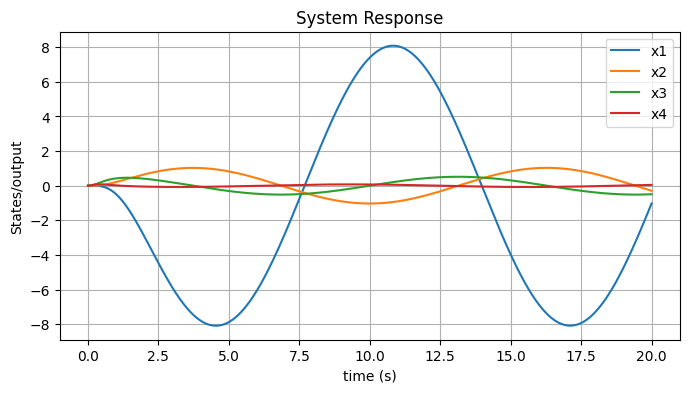

In [7]:
plt.figure(figsize=(8, 4))
# plt.plot(t_out, y_out[:,0], label="y1")
# plt.plot(t_out, y_out[:,1], label="y2")
plt.plot(t_out, x_out[:,0], label="x1")
plt.plot(t_out, x_out[:,1], label="x2")
plt.plot(t_out, x_out[:,2], label="x3")
plt.plot(t_out, x_out[:,3], label="x4")
plt.xlabel("time (s)")
plt.ylabel("States/output")
plt.title("System Response")
plt.legend()
plt.grid(True)
plt.show()

## Transfer Matrix

In [9]:
matA = np.array(A)
matB = np.array(B)
matC = np.array(C)
